In [12]:
#####     cRoot/cVeg ratio     #####
# 处理 cRoot/cVeg ratio，计算 AGC
import numpy as np
from joblib import load
import warnings

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
lat, lon = np.arange(-60, 90.1, 1), np.arange(0, 360.1, 1)

from typing import OrderedDict

AllData:OrderedDict = load("./Data/CMIP6_raw.joblib")
print(f"All Models: {len(AllData)}")


All Models: 30


In [13]:
### ----- Calculate cRoot/cVeg ratio ----- ###
ratio_data = OrderedDict()

for model, data in AllData.items():
    cVeg, cRoot = data["cVeg"], data["cRoot"]
    if cRoot is None:
        continue
    ratio = cRoot / cVeg
    ratio[cVeg <= 0] = np.nan
    ratio = np.clip(ratio, 0, 1)
    ratio_data[model] = ratio

# MME Mean cRoot/cVeg Ratio
values = list(ratio_data.values())
with warnings.catch_warnings(action="ignore"):
    RatioMean = np.nanmean(values, axis=0)  # MME Mean [H, W]
    RatioStd = np.nanstd(values, axis=0)  # MME Std [H, W]
print(f"Ratio completed!  {len(ratio_data)} Models;  {RatioMean.shape}")

### ----- Calculate AGB Carbon ----- ###
AGCs = OrderedDict()

for model, data in AllData.items():
    cVeg, cRoot = data["cVeg"], data["cRoot"]
    if cRoot is None:  # 根据 ratio 填充 cRoot 缺失
        cRoot = cVeg * RatioMean
    cAGB = cVeg - cRoot
    cAGB = np.clip(cAGB, 0, None)
    AGCs[model] = cAGB.astype(np.float32)

#AGBC_PATH = "./CMIP6_AGBC.npz"
#np.savez(AGBC_PATH, **AGCs)
#print(f"AGC completed!  Saved to: {AGBC_PATH}")

MeanAGC = np.nanmean(list(AGCs.values()), axis=0)  # [H, W]
MeanAGC[MeanAGC<=0] = np.nan
print(f"Global Mean AGB Carbon: {np.nanmean(MeanAGC):.2f} PgC/ha")


Ratio completed!  18 Models;  (180, 360)
Global Mean AGB Carbon: 26.88 PgC/ha


C:\Users\Admin\AppData\Local\Temp\ipykernel_9244\4129237413.py:35: RuntimeWarning: Mean of empty slice
  MeanAGC = np.nanmean(list(AGCs.values()), axis=0)  # [H, W]


In [14]:
### Apply Tree Mask
TreeMask = load("./Data/Masks/treemask.joblib")
RatioMean[TreeMask<=0] = np.nan
RatioStd[TreeMask<=0] = np.nan

glb_mean, glb_std = np.nanmean(RatioMean), np.nanstd(RatioMean)
print(f"Global Mean Ratio: {glb_mean*100:.2f} % ± {glb_std*100:.2f}")
print(f"MME Uncertainty: {np.nanmean(RatioStd)*100:.2f} % ± {np.nanstd(RatioStd)*100:.2f}")


Global Mean Ratio: 19.37 % ± 1.42
MME Uncertainty: 12.32 % ± 2.65


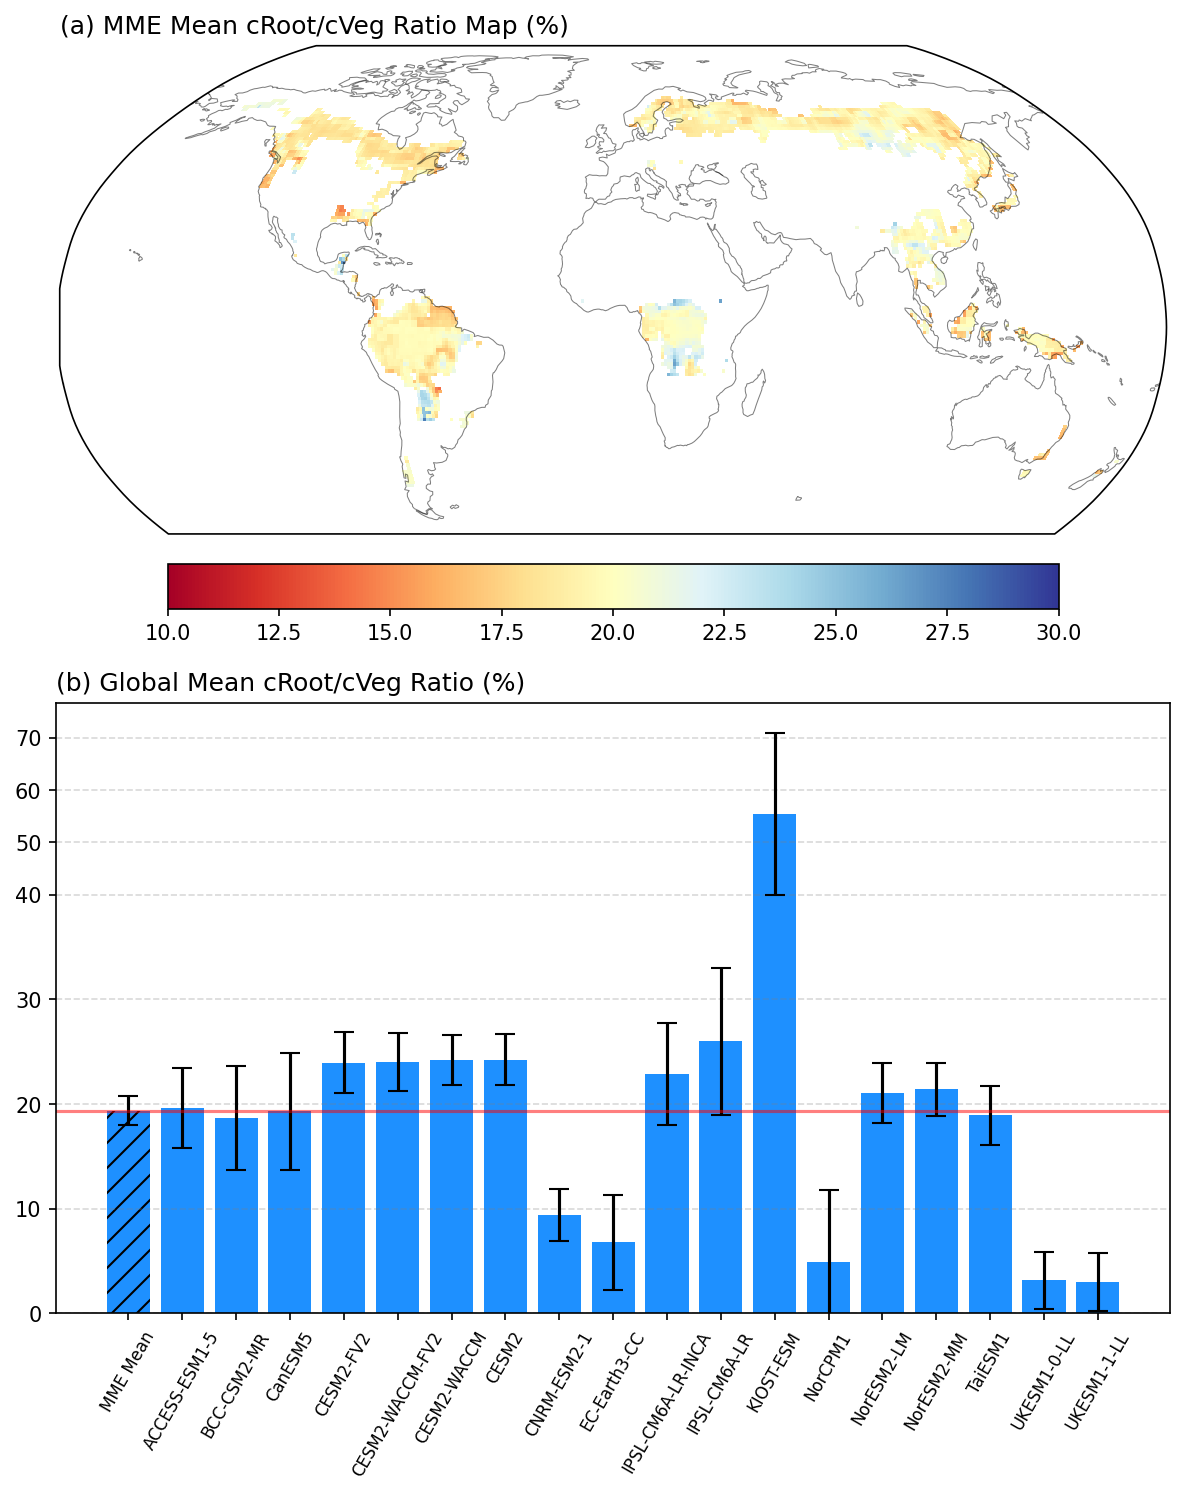

In [15]:
fig = plt.figure(figsize=(8, 10), dpi=150)

### ---------- Plot Ratio ---------- ###
ax = fig.add_subplot(2, 1, 1, projection=ccrs.Robinson())
ax.coastlines(linewidth=0.5, alpha=0.5)

img = ax.pcolormesh(lon, lat, RatioMean[30:]*100, vmin=10, vmax=30,
    cmap="RdYlBu", transform=ccrs.PlateCarree(), shading="flat")

plt.colorbar(img, ax=ax, orientation="horizontal", pad=0.05, shrink=0.8)
ax.set_title("(a) MME Mean cRoot/cVeg Ratio Map (%)", loc="left", fontsize=12)

### ---------- Ratio Bars ---------- ###
ax = fig.add_subplot(2, 1, 2)

xval = list(np.arange(len(ratio_data)))
yval = [np.nanmean(v[TreeMask])*100 for v in ratio_data.values()]  # 0~100 (%)
yerr = [np.nanstd(v[TreeMask])*100 for v in ratio_data.values()]

ax.bar(-1, glb_mean*100, width=0.8, color="dodgerblue", hatch="//")
ax.bar(xval, yval, width=0.8, color="dodgerblue")
ax.errorbar(-1, glb_mean*100, yerr=glb_std*100, fmt="none", capsize=5, ecolor="k")
ax.errorbar(xval, yval, yerr, fmt="none", capsize=5, ecolor="k")

ax.set_yscale("function", functions=(   # scale y-axis
    lambda x: np.where(x<=40, x, 40 + (x-40)/2),  # forward
    lambda y: np.where(y<=40, y, 40 + (y-40)*2),  # inverse
))
ax.set_xticks([-1]+xval, ["MME Mean",]+list(ratio_data.keys()), rotation=60, fontsize=8)
ax.axhline(glb_mean*100, color="red", linestyle="-", alpha=0.5)
ax.grid(True, axis="y", linestyle="--", color="gray", alpha=0.3)
ax.set_ylim(0, None)
ax.set_title("(b) Global Mean cRoot/cVeg Ratio (%)", loc="left", fontsize=12)

plt.tight_layout()
plt.show(fig)


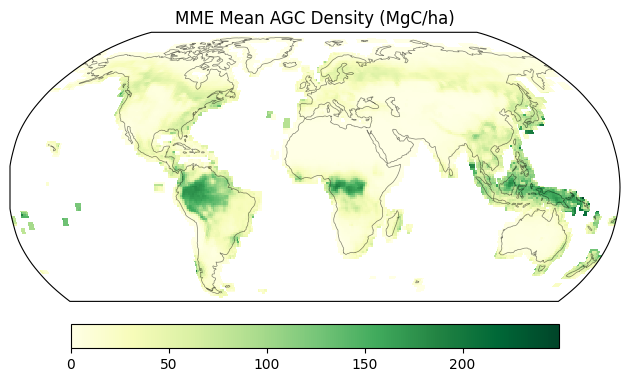

In [16]:
### ---------- Plot AGB Carbon ---------- ###
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})
ax.coastlines(linewidth=0.5, alpha=0.5)

img = ax.pcolormesh(lon, lat, MeanAGC[30:], vmin=0,
    cmap="YlGn", transform=ccrs.PlateCarree(), shading="flat")

plt.colorbar(img, ax=ax, orientation="horizontal", pad=0.05, shrink=0.8)
plt.title("MME Mean AGC Density (MgC/ha)")
plt.tight_layout()
plt.show(fig)
